# Assessing and Building Intuition

Investigate the data to build intuition.

In [12]:
import pandas as pd

df = pd.read_csv('store_data.csv')
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


# Cleaning data

In [15]:
import pandas as pd

df = pd.read_csv('store_data.csv')
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


In [4]:
# All entries are populated
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
week      200 non-null object
storeA    200 non-null int64
storeB    200 non-null int64
storeC    200 non-null int64
storeD    200 non-null int64
storeE    200 non-null int64
dtypes: int64(5), object(1)
memory usage: 9.5+ KB


In [7]:
# There isn't any duplicated
df.duplicated().sum()

0

In [8]:
df.dtypes

week      object
storeA     int64
storeB     int64
storeC     int64
storeD     int64
storeE     int64
dtype: object

In [13]:
# Parse week to date
df['week'] = pd.to_datetime(df['week'])
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


In [14]:
# Verifying again if is all ok
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
week      200 non-null datetime64[ns]
storeA    200 non-null int64
storeB    200 non-null int64
storeC    200 non-null int64
storeD    200 non-null int64
storeE    200 non-null int64
dtypes: datetime64[ns](1), int64(5)
memory usage: 9.5 KB


# Analyzing the data

In [18]:
import pandas as pd
% matplotlib inline

df = pd.read_csv('store_data.csv')
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f3107e6b128>,
      dtype=object)

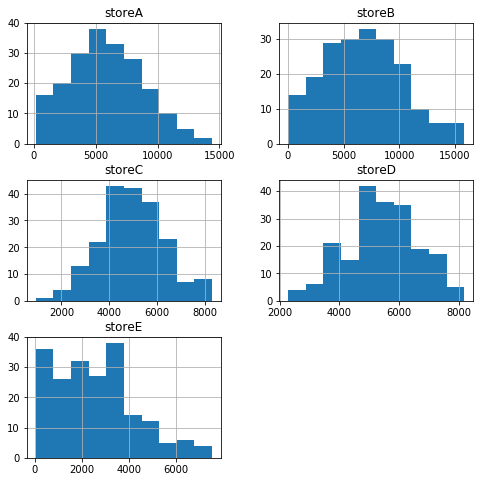

In [23]:
df.hist(figsize=(8,8))

In [24]:
df.tail(20)

,week,storeA,storeB,storeC,storeD,storeE
180,2017-10-15,8556,11984,4792,5995,2508
181,2017-10-22,3751,697,3990,4236,360
182,2017-10-29,4997,9759,4290,4568,2393
183,2017-11-05,12785,1800,6163,5157,578
184,2017-11-12,137,12261,5455,7695,2599
185,2017-11-19,9960,8529,4501,7631,505
186,2017-11-26,6866,5011,5401,4736,3232
187,2017-12-03,5179,3850,6121,6778,113
188,2017-12-10,9348,5624,5446,5448,227
189,2017-12-17,5310,8647,5680,7049,3578


In [29]:
# Average of sales
df.mean()

storeA    5865.480
storeB    6756.710
storeC    4942.105
storeD    5431.405
storeE    2580.025
dtype: float64

In [27]:
# Total sales of the last month
df_total_sales = df[df['week'] >= '2018-02-04']
df_total_sales.head()

,week,storeA,storeB,storeC,storeD,storeE
196,2018-02-04,4853,6503,4187,5956,1458
197,2018-02-11,9202,3677,4540,6186,243
198,2018-02-18,3512,7511,4151,5596,3501
199,2018-02-25,7560,6904,3569,5045,2585


In [32]:
# Total sales of the last 3 month
df_last_three_month_sales = df[df['week'] >= '2017-12-01']
df_last_three_month_sales.iloc[:, 1:].sum()

storeA    87591
storeB    79394
storeC    66538
storeD    75190
storeE    27334
dtype: int64

In [36]:
# In what week storeC make it worst sales?
df[df['storeC'] == df['storeC'].min()]

,week,storeA,storeB,storeC,storeD,storeE
9,2014-07-06,8567,3228,927,3277,168


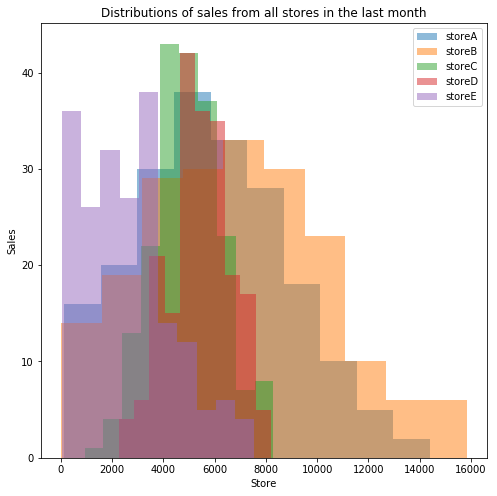

In [49]:
import matplotlib.pyplot as plt
% matplotlib inline

#df_lm = df[df['week'] >= '2017-01-01']
df_lm = df

fig, ax = plt.subplots(figsize=(8, 8))
ax.hist(df_lm['storeA'], alpha=0.5, label='storeA')
ax.hist(df_lm['storeB'], alpha=0.5, label='storeB')
ax.hist(df_lm['storeC'], alpha=0.5, label='storeC')
ax.hist(df_lm['storeD'], alpha=0.5, label='storeD')
ax.hist(df_lm['storeE'], alpha=0.5, label='storeE')
ax.set_title('Distributions of sales from all stores in the last month')
ax.set_xlabel('Store')
ax.set_ylabel('Sales')
ax.legend(loc='upper right')
plt.show()

# Communication

In [50]:
import pandas as pd
% matplotlib inline

df = pd.read_csv('store_data.csv')
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


In [53]:
# Parse week to date
df['week'] = pd.to_datetime(df['week'])
df.head()

,week,storeA,storeB,storeC,storeD,storeE
0,2014-05-04,2643,8257,3893,6231,1294
1,2014-05-11,6444,5736,5634,7092,2907
2,2014-05-18,9646,2552,4253,5447,4736
3,2014-05-25,5960,10740,8264,6063,949
4,2014-06-01,7412,7374,3208,3985,3023


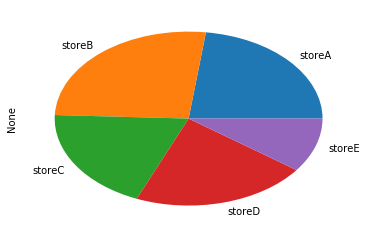

In [54]:
# Compare between store which sell more
df.mean().plot(kind='pie')

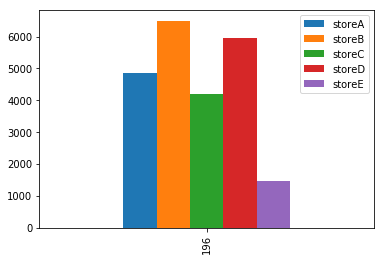

In [61]:
sales = df[df['week'] == '2018-02-04']
sales.iloc[:,1:].plot(kind='bar')